# 13 · 置信度校准，以及游戏的判定规则

**问题。**模型给出 10 个数字的概率后，游戏还要决定"这一笔算打中哪个妖怪"。现在的 `decide()`（`js/game/handwriting.js`）是手调的几条阈值：

```js
if (best.d === top.d && top.p >= 0.3) → hit top                        // 最可能的数字就在屏幕上
if (best.p >= 0.2 && best.p >= 0.35 * top.p) → hit best (corrected)    // 屏幕上的某个答案也有一定可能
if (top.p >= 0.5) → miss                                               // 很确定写的是屏幕上没有的数字
else → unclear                                                         // 请重写
```

这些阈值是给旧模型调的，而且有两个隐含的问题：

1. **概率的含义随模型变。**notebook 08 发现，用 label smoothing 训练的 CNN **信心不足**（说 70% 时其实对 90% 以上）；融合后的概率又是另一种尺度。同样的阈值 0.3，在不同模型上意思不一样。
2. **规则没有把"玩家大概率写的是屏幕上的答案"当成明确的先验**，也没有区分不同错误的代价。

**这一本做三件事：**

1. **校准**：温度缩放 [19]（只有一个参数 $T$，在验证集上拟合），让概率可以直接当成"对的可能性"。
2. **新的判定规则**：贝叶斯式的规则（"概率 × 候选先验"），参数按**错误代价**在验证集上选。
3. **模拟游戏**：屏幕上 1–4 个答案，玩家写**对**的答案（应该打中）和写**错**的答案（算错了，应该判 miss），比较新旧规则。

**比较的模型**（都用种子 42，即实际会上线的单个模型）：现在游戏里的模型（notebook 06 的 `ship_cnn_final`）、09 的图像模型 C、12 的 resnet、12 的 resnet + 轨迹融合、12b 的 ink_glance。

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from scipy.optimize import minimize_scalar

from fingermath import evaluate, recipe

REAL = Path('../cache/real'); RESULTS = Path('../results'); MODEL_DIR = Path('../cache/models')
plt.rcParams['figure.dpi'] = 110

meta, x_real = recipe.real_meta()
y = meta.label.to_numpy()
SPLITS = recipe.eval_splits(meta)
VAL = np.concatenate([SPLITS['val: pen'], SPLITS['val: finger']])

P9 = dict(np.load(REAL / 'probs09.npz')); P12 = dict(np.load(REAL / 'probs12.npz')); P12b = dict(np.load(REAL / 'probs12b.npz'))
r12 = json.loads((RESULTS / '12_image_architectures.json').read_text(encoding='utf-8'))

def fuse(p_img, p_traj, w):
    z = w * np.log(p_img + 1e-7) + (1 - w) * np.log(p_traj + 1e-7)
    e = np.exp(z - z.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

shipped = keras.models.load_model(MODEL_DIR / 'ship_cnn_final.keras')
MODELS = {
    'shipped (06)': shipped.predict(x_real[..., None], batch_size=2048, verbose=0),
    'image C (09)': P9['C_42'],
    'resnet (12)': P12['resnet_42'],
    'resnet + trajectory (12)': fuse(P12['resnet_42'], P12b['trajectory (11)|42'], r12['fusion_with_trajectory']['resnet']['w']),
    'ink_glance (12b)': P12b['ink_glance|42'],
}
for k, p in MODELS.items():
    print(f'{k:26s}', {s: round(100 * float((p[i].argmax(1) == y[i]).mean()), 2) for s, i in SPLITS.items()})

shipped (06)               {'val: pen': 97.86, 'val: finger': 98.42, 'test: pen': 96.26, 'test: finger': 98.36}
image C (09)               {'val: pen': 99.6, 'val: finger': 98.91, 'test: pen': 98.4, 'test: finger': 98.84}
resnet (12)                {'val: pen': 99.6, 'val: finger': 99.37, 'test: pen': 98.23, 'test: finger': 99.26}
resnet + trajectory (12)   {'val: pen': 99.73, 'val: finger': 99.41, 'test: pen': 98.66, 'test: finger': 99.54}
ink_glance (12b)           {'val: pen': 99.67, 'val: finger': 99.22, 'test: pen': 98.94, 'test: finger': 99.08}


## 1. 校准

**ECE**（期望校准误差）：把样本按模型的最高概率分成 15 段，每段里"平均信心"和"实际准确率"之差，按样本数加权平均。0 表示完全可信。

**温度缩放**：$p_T = \mathrm{softmax}(\log p / T)$。$T > 1$ 让概率更平，$T < 1$ 让概率更尖。$T$ 在验证集上用最大似然拟合。它**不改变**哪个数字最可能，只改变"有多确定"。

In [2]:
def temp(p, t):
    z = np.log(p + 1e-7) / t
    e = np.exp(z - z.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

def ece(p, yy, bins=15):
    conf, ok = p.max(1), p.argmax(1) == yy
    edges = np.linspace(0, 1, bins + 1); out = 0
    for a, b in zip(edges[:-1], edges[1:]):
        m = (conf > a) & (conf <= b)
        if m.any():
            out += m.mean() * abs(conf[m].mean() - ok[m].mean())
    return out

def nll(p, yy):
    return float(-np.log(p[np.arange(len(yy)), yy] + 1e-9).mean())

T = {}
cal_rows = []
for k, p in MODELS.items():
    T[k] = minimize_scalar(lambda t: nll(temp(p[VAL], t), y[VAL]), bounds=(0.05, 5), method='bounded').x
    for s in ['test: pen', 'test: finger']:
        i = SPLITS[s]
        cal_rows.append({'model': k, 'test set': s, 'T': T[k], 'ECE before %': 100 * ece(p[i], y[i]), 'ECE after %': 100 * ece(temp(p[i], T[k]), y[i]),
                         'NLL before': nll(p[i], y[i]), 'NLL after': nll(temp(p[i], T[k]), y[i])})
CAL = {k: temp(p, T[k]) for k, p in MODELS.items()}
pd.DataFrame(cal_rows).round(3)

,model,test set,T,ECE before %,ECE after %,NLL before,NLL after
0,shipped (06),test: pen,0.582,9.348,1.291,0.212,0.136
1,shipped (06),test: finger,0.582,8.802,0.364,0.141,0.060
2,image C (09),test: pen,0.561,8.125,0.546,0.132,0.058
3,image C (09),test: finger,0.561,8.460,0.259,0.123,0.043
4,resnet (12),test: pen,0.534,9.159,1.130,0.155,0.086
5,resnet (12),test: finger,0.534,9.486,0.215,0.121,0.027
6,resnet + trajectory (12),test: pen,0.493,9.784,0.734,0.138,0.047
7,resnet + trajectory (12),test: finger,0.493,10.504,0.169,0.125,0.018
8,ink_glance (12b),test: pen,0.527,8.496,0.494,0.124,0.046
9,ink_glance (12b),test: finger,0.527,9.284,0.226,0.126,0.036


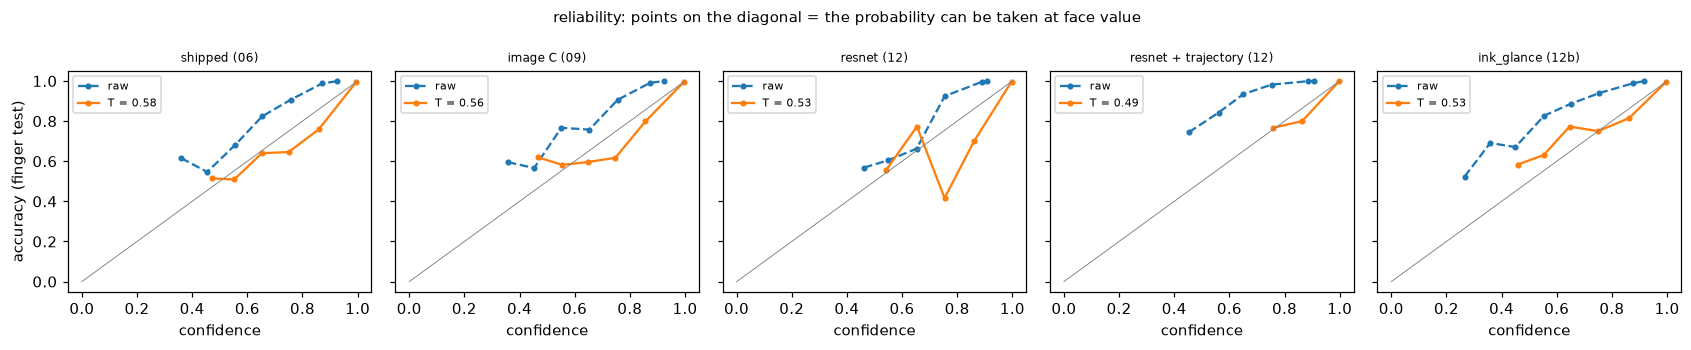

In [3]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(3.1 * len(MODELS), 3.2), sharey=True)
i = SPLITS['test: finger']
for ax, (k, p) in zip(axes, MODELS.items()):
    for q, lab, st in [(p, 'raw', '--'), (CAL[k], f'T = {T[k]:.2f}', '-')]:
        conf, ok = q[i].max(1), q[i].argmax(1) == y[i]
        edges = np.linspace(0, 1, 11); mids, accs = [], []
        for a, b in zip(edges[:-1], edges[1:]):
            m = (conf > a) & (conf <= b)
            if m.sum() > 20: mids.append(conf[m].mean()); accs.append(ok[m].mean())
        ax.plot(mids, accs, st, marker='o', ms=3, label=lab)
    ax.plot([0, 1], [0, 1], color='gray', lw=0.6); ax.set_title(k, fontsize=8); ax.set_xlabel('confidence'); ax.legend(fontsize=7)
axes[0].set_ylabel('accuracy (finger test)')
plt.suptitle('reliability: points on the diagonal = the probability can be taken at face value', fontsize=10); plt.tight_layout(); plt.show()

## 2. 游戏场景的模拟

每个测试样本模拟两种情况，屏幕上有 $k \in \{1, 2, 3, 4\}$ 个**不同的**答案（游戏里答案是 0–9 的一位数）：

- **写对了**：玩家写的数字（样本的标签）是屏幕上的答案之一，其余 $k-1$ 个随机。理想结果：打中这个答案。
- **算错了**：玩家写的数字不在屏幕上（$k$ 个答案都随机取自其他数字）。理想结果：判 miss（或请重写），**绝不能**打中某个妖怪。

可能的结果和它们对玩家的意义：

| 情况 | 结果 | 代价 | 理由 |
|---|---|---|---|
| 写对 | 打中正确的妖怪 | 0 | |
| 写对 | **打中另一个妖怪** | 5 | 最糟：玩家写对了，却被惩罚，还打错了目标 |
| 写对 | 判 miss | 3 | 写对却算错，扣血 |
| 写对 | 请重写（unclear） | 1 | 只是慢了一点 |
| 算错 | 判 miss / 请重写 | 0 | 正确 |
| 算错 | **打中某个妖怪** | 2 | 奖励了错误的计算；但玩家本来就错了，体验上没那么糟 |

代价是我按游戏体验定的，可以讨论；下面也会给出不依赖代价的完整比较表。玩家"写对"的比例 $\pi$ 设为 0.85（游戏的难度系统会把正确率维持在较高水平），并检验 0.7 和 0.95 时结论是否改变。

In [4]:
COST = {('right', 'hit'): 0, ('right', 'wrong'): 5, ('right', 'miss'): 3, ('right', 'unclear'): 1,
        ('wrong', 'miss'): 0, ('wrong', 'unclear'): 0, ('wrong', 'hit'): 2}
KS = [1, 2, 3, 4]

def scenarios(idx, seed=0):
    """For each sample and k: answers when written right / when written wrong (fixed draws, shared by every rule)."""
    rng = np.random.default_rng(seed)
    out = []
    for i in idx:
        t = y[i]; others = [d for d in range(10) if d != t]
        for k in KS:
            out.append((i, k, 'right', frozenset([t, *rng.choice(others, k - 1, replace=False)])))
            out.append((i, k, 'wrong', frozenset(rng.choice(others, k, replace=False))))
    return out

SC = {name: scenarios(SPLITS[name], seed=13) for name in SPLITS}

def old_rule(p, answers):
    kind, d = evaluate.decide(p, answers)
    return kind, d

def outcome(case, kind, d, t):
    if case == 'right':
        return 'hit' if kind == 'hit' and d == t else 'wrong' if kind == 'hit' else kind
    return 'hit' if kind == 'hit' else kind

def run(rule, p, sc, pi=0.85):
    rows = []
    for i, k, case, ans in sc:
        kind, d = rule(p[i], ans, pi) if rule is not old_rule else old_rule(p[i], ans)
        rows.append((k, case, outcome(case, kind, d, y[i])))
    return pd.DataFrame(rows, columns=['k', 'case', 'result'])

def summarise(df, pi=0.85):
    """Rates within each case, and the expected cost per written answer (right with probability pi)."""
    r = df.groupby('case').result.value_counts(normalize=True).unstack(fill_value=0) * 100
    right, wrong = r.loc['right'], r.loc['wrong']
    cost = pi * sum(COST[('right', o)] * right.get(o, 0) for o in ['hit', 'wrong', 'miss', 'unclear']) / 100 \
        + (1 - pi) * sum(COST[('wrong', o)] * wrong.get(o, 0) for o in ['hit', 'miss', 'unclear']) / 100
    return {'right: hit %': right.get('hit', 0), 'right: wrong yokai %': right.get('wrong', 0), 'right: miss %': right.get('miss', 0),
            'right: rewrite %': right.get('unclear', 0), 'wrong maths: hit a yokai %': wrong.get('hit', 0), 'expected cost': cost}

## 3. 新规则：先验 × 概率，按代价选阈值

1. 先用校准后的概率 $p(d \mid x)$。
2. 加上屏幕的先验：屏幕上的答案合计占 $\pi$，平均分；其他数字合计占 $1 - \pi$。训练时 10 个数字是均匀的，所以后验 $\propto p(d \mid x) \cdot \text{prior}(d)$。
3. 屏幕上后验最大的答案记为 $a$，后验为 $q_a$；所有不在屏幕上的数字的后验合计 $q_\text{off}$。
   - $q_a \ge \tau_\text{hit}$ → **打中** $a$；
   - 否则，$q_\text{off} \ge \tau_\text{miss}$ → **miss**；
   - 否则 → **请重写**。

两个阈值在**验证集**上网格搜索，让预期代价最小；$\pi$ 固定为 0.85（游戏里用同一个值）。每个模型分别选阈值。

In [5]:
def new_rule_factory(t_hit, t_miss):
    def rule(p, answers, pi):
        a = np.array(sorted(answers)); k = len(a)
        prior = np.full(10, (1 - pi) / (10 - k)); prior[a] = pi / k
        q = p * prior; q /= q.sum()
        best = a[np.argmax(q[a])]
        if q[best] >= t_hit:
            return 'hit', int(best)
        off = 1 - q[a].sum()
        return ('miss', int(np.argmax(np.where(np.isin(np.arange(10), a), -1, q)))) if off >= t_miss else ('unclear', int(best))
    return rule

GRID_HIT = [0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
GRID_MISS = [0.5, 0.6, 0.7, 0.8, 0.9]
val_sc = SC['val: pen'] + SC['val: finger']
CHOSEN = {}
for k, p in CAL.items():
    best = None
    for th in GRID_HIT:
        for tm in GRID_MISS:
            c = summarise(run(new_rule_factory(th, tm), p, val_sc))['expected cost']
            if best is None or c < best[0]:
                best = (c, th, tm)
    CHOSEN[k] = best[1:]
    print(f'{k:26s} tau_hit {best[1]:.2f}  tau_miss {best[2]:.2f}  (validation cost {best[0]:.3f})')

shipped (06)               tau_hit 0.80  tau_miss 0.90  (validation cost 0.024)


image C (09)               tau_hit 0.60  tau_miss 0.90  (validation cost 0.015)


resnet (12)                tau_hit 0.40  tau_miss 0.90  (validation cost 0.010)


resnet + trajectory (12)   tau_hit 0.70  tau_miss 0.90  (validation cost 0.009)


ink_glance (12b)           tau_hit 0.70  tau_miss 0.90  (validation cost 0.011)


## 4. 新旧规则对比（测试集）

"旧规则"用模型的原始概率（游戏现在就是这样）；"新规则"用校准后的概率和上面选出的阈值。所有 $k$ 合在一起。

In [6]:
rows = []
for s in ['test: pen', 'test: finger']:
    for k, p in MODELS.items():
        rows.append({'test set': s, 'model': k, 'rule': 'old decide()', **summarise(run(old_rule, p, SC[s]))})
        rows.append({'test set': s, 'model': k, 'rule': 'new', **summarise(run(new_rule_factory(*CHOSEN[k]), CAL[k], SC[s]))})
cmp = pd.DataFrame(rows)
cmp.round(2)

,test set,model,rule,right: hit %,right: wrong yokai %,right: miss %,right: rewrite %,wrong maths: hit a yokai %,expected cost
0,test: pen,shipped (06),old decide(),97.09,0.66,1.91,0.34,1.77,0.09
1,test: pen,shipped (06),new,96.68,0.47,0.34,2.51,1.44,0.05
2,test: pen,image C (09),old decide(),98.77,0.26,0.64,0.32,0.69,0.03
3,test: pen,image C (09),new,98.98,0.24,0.16,0.62,0.76,0.02
4,test: pen,resnet (12),old decide(),98.41,0.31,1.16,0.13,0.74,0.05
5,test: pen,resnet (12),new,98.72,0.32,0.46,0.49,0.89,0.03
6,test: pen,resnet + trajectory (12),old decide(),99.04,0.23,0.55,0.19,0.54,0.03
7,test: pen,resnet + trajectory (12),new,99.04,0.17,0.17,0.61,0.54,0.02
8,test: pen,ink_glance (12b),old decide(),99.14,0.18,0.57,0.11,0.42,0.02
9,test: pen,ink_glance (12b),new,99.14,0.14,0.25,0.47,0.44,0.02


### 4.1 按屏幕上答案的个数

以 resnet + 轨迹（目前最强的候选）在手指测试集上为例。

In [7]:
KEY = 'resnet + trajectory (12)'
per_k = []
for name, rule, p in [('old decide()', old_rule, MODELS[KEY]), ('new', new_rule_factory(*CHOSEN[KEY]), CAL[KEY])]:
    df = run(rule, p, SC['test: finger'])
    for k in KS:
        per_k.append({'rule': name, 'answers on screen': k, **summarise(df[df.k == k])})
pd.DataFrame(per_k).round(2)

,rule,answers on screen,right: hit %,right: wrong yokai %,right: miss %,right: rewrite %,wrong maths: hit a yokai %,expected cost
0,old decide(),1,99.77,0.00,0.20,0.03,0.12,0.01
1,old decide(),2,99.75,0.05,0.18,0.02,0.24,0.01
2,old decide(),3,99.71,0.10,0.16,0.03,0.36,0.01
3,old decide(),4,99.69,0.14,0.14,0.03,0.44,0.01
4,new,1,99.86,0.00,0.06,0.07,0.21,0.00
5,new,2,99.76,0.03,0.06,0.15,0.26,0.00
6,new,3,99.64,0.06,0.06,0.24,0.32,0.01
7,new,4,99.56,0.10,0.06,0.29,0.29,0.01


### 4.2 对 $\pi$ 的敏感性

阈值按 $\pi = 0.85$ 选好后固定，只改变评价时"写对"的真实比例（玩家更强或更弱）。

In [8]:
sens = []
for pi in [0.7, 0.85, 0.95]:
    for name, rule, p in [('old decide()', old_rule, MODELS[KEY]), ('new', new_rule_factory(*CHOSEN[KEY]), CAL[KEY])]:
        df = run(rule, p, SC['test: finger'])
        sens.append({'pi': pi, 'rule': name, 'expected cost': summarise(df, pi)['expected cost']})
pd.DataFrame(sens).pivot(index='pi', columns='rule', values='expected cost').round(3)

rule,new,old decide()
pi,,
0.70,0.006,0.008
0.85,0.006,0.008
0.95,0.006,0.009


## 5. 错误–拒识曲线

不看屏幕上的答案，只看模型自己：如果把最高概率低于某个阈值的样本都"请重写"，剩下的样本里错误率是多少 [20]。曲线越靠左下越好。用校准后的概率（不改变排序，所以曲线和原始概率相同）。

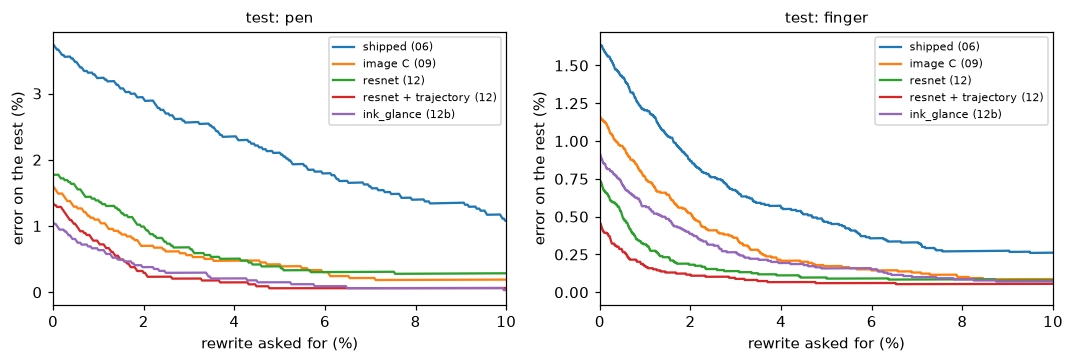

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, s in zip(axes, ['test: pen', 'test: finger']):
    i = SPLITS[s]
    for k, p in CAL.items():
        conf, ok = p[i].max(1), p[i].argmax(1) == y[i]
        order = np.argsort(-conf)
        kept = np.arange(1, len(i) + 1) / len(i)
        err = np.cumsum(~ok[order]) / np.arange(1, len(i) + 1)
        ax.plot(100 * (1 - kept), 100 * err, label=k)
    ax.set_xlim(0, 10); ax.set_xlabel('rewrite asked for (%)'); ax.set_ylabel('error on the rest (%)'); ax.set_title(s, fontsize=10)
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 6. 给游戏的规则（JS）

新规则只需要一个温度 $T$、两个阈值和 $\pi$。下面生成 `decide()` 的替换代码，参数取 resnet + 轨迹融合的结果（如果最后上线别的模型，换成上面表里对应的参数）。**这里只生成代码，不改游戏。**

In [10]:
t_hit, t_miss = CHOSEN[KEY]
js = f"""// Bayesian reading (research notebook 13): calibrated probabilities x the answers on screen.
const TEMP = {T[KEY]:.3f}, PI = 0.85, T_HIT = {t_hit:.2f}, T_MISS = {t_miss:.2f};
export function decide(probs) {{
  const answers = new Set(targets().map((e) => e.answer));
  const z = probs.map((p) => Math.log(p + 1e-7) / TEMP), m = Math.max(...z);
  const p = z.map((v) => Math.exp(v - m)); const s0 = p.reduce((a, b) => a + b, 0);
  const top = p.indexOf(Math.max(...p));
  if (!answers.size) return {{ kind: 'idle', d: top, p: p[top] / s0 }};
  const k = answers.size;
  const q = p.map((v, d) => v / s0 * (answers.has(d) ? PI / k : (1 - PI) / (10 - k)));
  const s = q.reduce((a, b) => a + b, 0);
  let best = -1; for (const d of answers) if (best < 0 || q[d] > q[best]) best = d;
  if (q[best] / s >= T_HIT) return {{ kind: 'hit', d: best, p: q[best] / s, ...(best !== top && {{ corrected: top }}) }};
  const off = 1 - [...answers].reduce((a, d) => a + q[d], 0) / s;
  if (off >= T_MISS) return {{ kind: 'miss', d: top, p: p[top] / s0 }};
  return {{ kind: 'unclear', d: top, p: p[top] / s0 }};
}}"""
print(js)

// Bayesian reading (research notebook 13): calibrated probabilities x the answers on screen.
const TEMP = 0.493, PI = 0.85, T_HIT = 0.70, T_MISS = 0.90;
export function decide(probs) {
  const answers = new Set(targets().map((e) => e.answer));
  const z = probs.map((p) => Math.log(p + 1e-7) / TEMP), m = Math.max(...z);
  const p = z.map((v) => Math.exp(v - m)); const s0 = p.reduce((a, b) => a + b, 0);
  const top = p.indexOf(Math.max(...p));
  if (!answers.size) return { kind: 'idle', d: top, p: p[top] / s0 };
  const k = answers.size;
  const q = p.map((v, d) => v / s0 * (answers.has(d) ? PI / k : (1 - PI) / (10 - k)));
  const s = q.reduce((a, b) => a + b, 0);
  let best = -1; for (const d of answers) if (best < 0 || q[d] > q[best]) best = d;
  if (q[best] / s >= T_HIT) return { kind: 'hit', d: best, p: q[best] / s, ...(best !== top && { corrected: top }) };
  const off = 1 - [...answers].reduce((a, d) => a + q[d], 0) / s;
  if (off >= T_MISS) return { kind: 'miss', d: top, p: p[top

## 7. 保存

In [11]:
out = {'temperature': T, 'thresholds': {k: {'hit': v[0], 'miss': v[1]} for k, v in CHOSEN.items()}, 'pi': 0.85, 'cost': {f'{a}/{b}': c for (a, b), c in COST.items()},
       'calibration': cal_rows, 'comparison': cmp.round(4).to_dict(orient='records'), 'per_k': per_k, 'sensitivity': sens, 'js': js}
(RESULTS / '13_calibration_and_decision.json').write_text(json.dumps(out, indent=1, default=float), encoding='utf-8')
print('saved results/13_calibration_and_decision.json')

saved results/13_calibration_and_decision.json


## 8. 结论

**1. 所有模型都"信心不足"，一个温度参数就能修好。**拟合出的温度都在 0.49–0.58 之间（$T < 1$ 表示要把概率变尖）：模型说 70% 的时候，实际对的比例远高于 70%。这是训练时 label smoothing（0.1）的已知副作用 [10]。温度缩放后，ECE 从 8–10% 降到 0.2–1.3%，测试集上的负对数似然下降 35–85%。它不改变任何一个预测，只是让概率能直接当成"对的可能性"用，这对任何阈值规则都是前提。

**2. 新规则在每个模型上都降低了预期代价 25–36%。**（代价越低越好；测试集，屏幕上 1–4 个答案合计）

| 模型 | 手指：旧规则 | 手指：新规则 | 触控笔：旧规则 | 触控笔：新规则 |
|---|---|---|---|---|
| 现在游戏里的模型（06） | 0.0330 | 0.0222 | 0.0851 | 0.0543 |
| resnet + 轨迹（12） | 0.0085 | **0.0059** | 0.0269 | **0.0185** |

主要的变化是**把"写对了却被判 miss"换成"请重写"**：以 resnet + 轨迹在手指上为例，写对时被判 miss 从 0.17% 降到 0.06%，打错妖怪从 0.07% 降到 0.05%，代价是请重写从 0.03% 升到 0.19%。旧规则的 `top.p >= 0.5 → miss` 在信心不足的模型上太容易触发；新规则只有在"不在屏幕上的数字"的后验合计超过 90% 时才判 miss。"算错了却打中妖怪"两者差不多（0.3% 左右）。结论对玩家正确率 $\pi$ 不敏感（0.7–0.95 都是新规则低约 25%）。

**3. 但更大的改进来自模型本身。**从"现在游戏里的模型 + 旧规则"到"resnet + 轨迹 + 新规则"，预期代价在手指上下降 82%（0.0330 → 0.0059），触控笔上下降 78%。写对时正确打中的比例：手指 98.93% → 99.71%，触控笔 97.09% → 99.04%；打错妖怪：手指 0.26% → 0.05%，触控笔 0.66% → 0.17%。

**4. 屏幕上的答案越多，越容易打错妖怪**（resnet + 轨迹，手指：1 个答案 0%，4 个答案 0.10–0.14%），两种规则都一样，这是任务本身的难度。新规则在答案多时更倾向于请重写，而不是猜。

**5. 阈值和模型绑定。**选出的 $\tau_\text{hit}$ 从 0.4（resnet）到 0.8（现在的模型）不等，所以换模型时必须一起换温度和阈值。第 6 节给出了 resnet + 轨迹对应的 JS 代码，只需要 4 个常数；其他模型的参数在 `results/13_calibration_and_decision.json` 里。

**局限。**代价是我按游戏体验定的；"写对的比例"是假设的；模拟里屏幕上的答案是随机的，而游戏的出题器会让答案彼此不同、并且约 30% 的时候重复已有的答案（多个妖怪同一个答案，这只会让判定更容易）。这些都只影响阈值的微调，不影响"校准 + 先验"这个结构。